# Phase 8 — Threshold Tuning and Honest Validation

**Purpose.** Turn classifier probabilities into the final match lists and measure the expected leaderboard score. This is the first phase that reads **validation labels**.
The model (Phase 7) was trained on train queries only, so validation is genuinely unseen.

**Plan**
1. Load validation candidates, Phase 7 scores, and validation truth (6,000 sampled validation queries). Report PR-AUC and the retrieval ceiling.
2. Baseline: fixed 0.5 threshold.
3. Global threshold sweep (macro F0.5 per S1 entity; entities with no true match score 1.0 for an empty list).
4. Alternative decision rules: per-country threshold, relative-to-best rule, per-query cap.
5. **Honest estimate by cross-fitting**: tune each rule on 4/5 of the validation entities, score on the remaining 1/5, repeat over 5 folds.
   The cross-fit mean is the number to quote; the in-sample best is optimistic because it tunes on the data it is scored on.
6. Error profile by true-match count and country; bootstrap confidence interval.
7. Freeze the rule and write `threshold_config.json`.

**Decision rules (fixed before looking at results).** A rule replaces the global threshold only if its cross-fit mean beats the global rule's by more than 0.002;
otherwise the simpler global threshold is kept. The final threshold is chosen on all validation entities and smoothed (middle of the region within 0.001 of the best).

In [1]:
import os, sys, json, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import eval_utils as EU

ROOT = "../../../"; INTERIM = ROOT + "dataset/interim"
SEED = 42
pd.set_option("display.width", 170)

## 1. Load validation data

In [2]:
cv = pd.read_pickle(INTERIM + "/candidates_val.pkl")
sv = pd.read_pickle(INTERIM + "/val_scores.pkl")
assert (cv["s1_id"].values == sv["s1_id"].values).all(), "scores not aligned with candidates"
P4 = pickle.load(open(INTERIM + "/phase4_truth_and_queries.pkl", "rb"))
ents = cv["s1_id"].unique().tolist()
tv = P4["truth"]["val"]; tv = tv[tv["s1_id"].isin(set(ents))]
ntrue = tv.groupby("s1_id").size()
country = cv.drop_duplicates("s1_id").set_index("s1_id")["country"].reindex(ents)
q = cv["s1_id"].values; y = cv["label"].values; p = sv["score"].values
print(f"{len(ents):,} validation queries | {len(cv):,} candidate pairs | {y.mean():.2%} positive | {int((ntrue>0).sum()):,} entities have >=1 true match")
print("true matches per entity:", ntrue.reindex(ents).fillna(0).astype(int).clip(upper=4).value_counts().sort_index().to_dict(), "(4 = 4+)")
print(f"PR-AUC on validation: {average_precision_score(y, p):.4f}")
# Retrieval ceiling: predict exactly the true candidates that retrieval found
ceil, _ = EU.macro_f05(ents, ntrue, q, y, y)
print(f"retrieval ceiling (perfect classifier on retrieved pool): macro F0.5 = {ceil:.4f}")

6,000 validation queries | 227,888 candidate pairs | 8.43% positive | 5,652 entities have >=1 true match
true matches per entity: {0: 348, 1: 337, 2: 1007, 3: 1434, 4: 2874} (4 = 4+)
PR-AUC on validation: 0.9976
retrieval ceiling (perfect classifier on retrieved pool): macro F0.5 = 0.9724


## 2–3. Baseline and global threshold sweep

baseline t=0.50: 0.9471
in-sample best  t=0.725: 0.9509   (optimistic)
plateau within 0.001 of best: [0.650, 0.775] -> smoothed threshold 0.700 (0.9508)


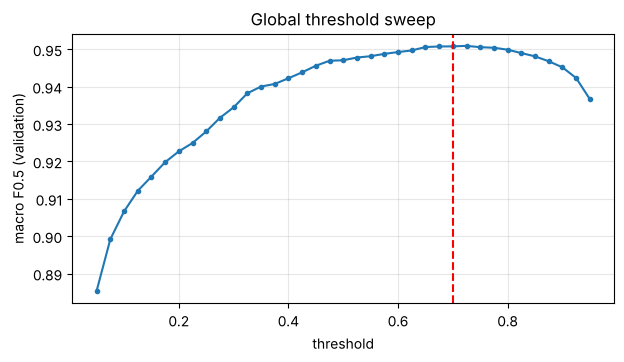

In [3]:
grid = np.round(np.arange(0.05, 0.96, 0.025), 3)
f_ent = {}     # per-entity F0.5 for each global threshold
for t in grid:
    f_ent[t] = EU.macro_f05(ents, ntrue, q, y, (p >= t).astype(int))[1]
F = pd.DataFrame(f_ent)                  # entities x thresholds
curve = F.mean()
base = curve.loc[0.5] if 0.5 in curve.index else None
tbest = curve.idxmax()
print(f"baseline t=0.50: {base:.4f}")
print(f"in-sample best  t={tbest:.3f}: {curve.max():.4f}   (optimistic)")
near = curve[curve >= curve.max() - 0.001].index
t_smooth = float(near[np.abs(near.values - np.median(near.values)).argmin()])
print(f"plateau within 0.001 of best: [{near.min():.3f}, {near.max():.3f}] -> smoothed threshold {t_smooth:.3f} ({curve.loc[t_smooth]:.4f})")
fig, ax = plt.subplots(figsize=(7, 3.5)); ax.plot(curve.index, curve.values, "-o", ms=3)
ax.axvline(t_smooth, color="r", ls="--"); ax.set_xlabel("threshold"); ax.set_ylabel("macro F0.5 (validation)"); ax.set_title("Global threshold sweep"); ax.grid(alpha=.3); plt.show()

## 4. Alternative decision rules
* **global** — predict if `p >= t`.
* **per-country** — separate `t` for India and US.
* **relative** — predict if `p >= t` **and** `p >= a * max(p in query)` (suppresses weaker look-alikes when one candidate is clearly best).
* **cap** — at most *N* predictions per query (top scores above `t`).

Each rule's parameters are scored per entity on the full grid so that the cross-fit below only needs to average subsets.

In [4]:
qmax = pd.Series(p).groupby(q).transform("max").values
rank = pd.Series(-p).groupby(q).rank(method="first").values
tg = np.round(np.arange(0.2, 0.96, 0.05), 3)
rules = {}
for t in tg:
    rules[("global", t)] = (p >= t)
for t in tg:
    for a in (0.3, 0.5, 0.7, 0.9):
        rules[("relative", t, a)] = (p >= t) & (p >= a * qmax)
for t in tg:
    for n in (2, 3, 4):
        rules[("cap", t, n)] = (p >= t) & (rank <= n)
FE = {k: EU.macro_f05(ents, ntrue, q, y, v.astype(int))[1] for k, v in rules.items()}
FE = pd.DataFrame(FE)
FE.columns = pd.MultiIndex.from_tuples([tuple(c) + (None,) * (3 - len(c)) for c in FE.columns])
print(f"{FE.shape[1]} rule settings scored")
best = {}
for kind in ("global", "relative", "cap"):
    sub = FE.xs(kind, axis=1, level=0, drop_level=False); m = sub.mean(); k = m.idxmax()
    best[kind] = (k, m.max()); print(f"{kind:9s} best in-sample {m.max():.4f}  params {k[1:]}")

# per-country thresholds (tune each country's threshold on its own entities)
cn = country.reindex(FE.index)
pc = {}
for c in cn.unique():
    sub = FE.xs("global", axis=1, level=0)[cn == c].mean(); pc[c] = (sub.idxmax()[0], sub.max())
print("per-country best t:", {c: v[0] for c, v in pc.items()})

128 rule settings scored
global    best in-sample 0.9508  params (np.float64(0.7), nan)
relative  best in-sample 0.9508  params (np.float64(0.7), np.float64(0.3))
cap       best in-sample 0.9385  params (np.float64(0.7), np.float64(4.0))
per-country best t: {'India': np.float64(0.75), 'US': np.float64(0.7)}


## 5. Honest estimate by 5-fold cross-fitting over entities
Within each fold: choose parameters for each rule on the other 4 folds, score on the held-out fold. The per-entity F0.5 values are pooled, so the mean is the cross-fit macro F0.5.

In [5]:
rs = np.random.default_rng(SEED); perm = rs.permutation(len(ents)); folds = np.array_split(perm, 5)
G = FE.xs("global", axis=1, level=0); R = FE.xs("relative", axis=1, level=0); C = FE.xs("cap", axis=1, level=0)
def crossfit(M):
    out = np.zeros(len(M)); chosen = []
    for f in folds:
        tr = np.setdiff1d(np.arange(len(M)), f); k = M.iloc[tr].mean().idxmax(); out[f] = M.iloc[f][k].values; chosen.append(k)
    return out, chosen
res = {}
res["global"] = crossfit(G); res["relative"] = crossfit(R); res["cap"] = crossfit(C)
# per-country cross-fit
out = np.zeros(len(G)); cch = []
for f in folds:
    tr = np.setdiff1d(np.arange(len(G)), f)
    for c in cn.unique():
        trc = tr[(cn.values[tr] == c)]; k = G.iloc[trc].mean().idxmax(); fc = f[cn.values[f] == c]; out[fc] = G.iloc[fc][k].values
res["per_country"] = (out, None)
base_f = np.asarray(F[0.5] if 0.5 in F.columns else F.iloc[:, 0])
rows = [("fixed 0.50 (no tuning)", base_f.mean())] + [(k, v[0].mean()) for k, v in res.items()]
T = pd.DataFrame(rows, columns=["rule", "cross-fit macro F0.5"]).set_index("rule")
T["gain vs global"] = T["cross-fit macro F0.5"] - T.loc["global", "cross-fit macro F0.5"]
print(T.round(4)); print("global thresholds chosen per fold:", [k for k in res["global"][1]])
print("relative params per fold:", res["relative"][1]); print("cap params per fold:", res["cap"][1])
cand = T.drop(["fixed 0.50 (no tuning)", "global"])
winner = cand["gain vs global"].idxmax()
USE = winner if cand.loc[winner, "gain vs global"] > 0.002 else "global"
print(f"\nDecision rule: best alternative = {winner} ({cand.loc[winner,'gain vs global']:+.4f}); needs > +0.0020 -> chosen rule: {USE}")

                        cross-fit macro F0.5  gain vs global
rule                                                        
fixed 0.50 (no tuning)                0.9471         -0.0035
global                                0.9505          0.0000
relative                              0.9504         -0.0002
cap                                   0.9384         -0.0122
per_country                           0.9504         -0.0002
global thresholds chosen per fold: [(np.float64(0.7), nan), (np.float64(0.7), nan), (np.float64(0.7), nan), (np.float64(0.7), nan), (np.float64(0.75), nan)]
relative params per fold: [(np.float64(0.7), np.float64(0.3)), (np.float64(0.65), np.float64(0.7)), (np.float64(0.7), np.float64(0.3)), (np.float64(0.7), np.float64(0.3)), (np.float64(0.75), np.float64(0.3))]
cap params per fold: [(np.float64(0.7), np.float64(4.0)), (np.float64(0.7), np.float64(4.0)), (np.float64(0.7), np.float64(4.0)), (np.float64(0.7), np.float64(4.0)), (np.float64(0.65), np.float64(4.0))]

Dec

## 6. Error profile and confidence interval
Where the remaining loss sits, using the chosen rule at its full-validation parameters.

In [6]:
if USE == "global":
    kbest = max(((("global", t), curve.loc[t]) for t in curve.index), key=lambda x: x[1])
    final_pred = (p >= t_smooth); final_cfg = {"rule": "global", "threshold": t_smooth}
elif USE == "relative":
    k = best["relative"][0]; final_pred = rules[(k[0], k[1], k[2])]; final_cfg = {"rule": "relative", "threshold": float(k[1]), "alpha": float(k[2])}
elif USE == "cap":
    k = best["cap"][0]; final_pred = rules[(k[0], k[1], k[2])]; final_cfg = {"rule": "cap", "threshold": float(k[1]), "cap": int(k[2])}
else:
    final_pred = None
    final_cfg = {"rule": "per_country", "thresholds": {c: float(v[0]) for c, v in pc.items()}}
    final_pred = np.zeros(len(p), bool)
    for c, v in pc.items(): final_pred |= (cv["country"].values == c) & (p >= v[0])
mac, fe = EU.macro_f05(ents, ntrue, q, y, final_pred.astype(int))
print(f"final rule {final_cfg} -> in-sample macro F0.5 {mac:.4f} (cross-fit estimate {T.loc[USE,'cross-fit macro F0.5']:.4f})")
nt = ntrue.reindex(ents).fillna(0).astype(int)
bk = pd.cut(nt, [-1, 0, 1, 2, 100], labels=["0 (singleton)", "1", "2", "3+"])
d = pd.DataFrame({"f05": fe.values, "bucket": bk.values, "country": cn.values})
print(d.groupby("bucket").f05.agg(["count", "mean"]).round(4))
print(d.groupby("country").f05.agg(["count", "mean"]).round(4))
# loss decomposition: how much is lost to retrieval vs the classifier
print(f"loss vs 1.0: retrieval ceiling gap {1-ceil:.4f}, classifier gap {ceil-mac:.4f}")
rs2 = np.random.default_rng(SEED); a = fe.values; bs = [a[rs2.integers(0, len(a), len(a))].mean() for _ in range(1000)]
print(f"95% bootstrap CI on the validation mean: [{np.percentile(bs,2.5):.4f}, {np.percentile(bs,97.5):.4f}]")
# precision / recall at pair level
tp = int((final_pred & (y == 1)).sum()); print(f"pair-level precision {tp/max(final_pred.sum(),1):.4f}, recall vs retrieved positives {tp/max(y.sum(),1):.4f}, recall vs ALL true matches {tp/len(tv):.4f}")

final rule {'rule': 'global', 'threshold': 0.7} -> in-sample macro F0.5 0.9508 (cross-fit estimate 0.9505)
               count    mean
bucket                      
0 (singleton)    348  0.9770
1                337  0.8808
2               1007  0.9377
3+              4308  0.9572
         count    mean
country               
India     2438  0.9363
US        3562  0.9607
loss vs 1.0: retrieval ceiling gap 0.0276, classifier gap 0.0216


95% bootstrap CI on the validation mean: [0.9473, 0.9541]
pair-level precision 0.9907, recall vs retrieved positives 0.9539, recall vs ALL true matches 0.8861


## 7. Freeze the rule

In [7]:
cfg = {"decision": final_cfg, "val_macro_f05_in_sample": round(mac, 4), "val_macro_f05_crossfit": round(float(T.loc[USE, 'cross-fit macro F0.5']), 4),
       "val_ceiling": round(ceil, 4), "val_pr_auc": round(float(average_precision_score(y, p)), 4), "n_val_queries": len(ents),
       "global_threshold_smoothed": t_smooth, "global_threshold_in_sample_best": float(tbest)}
json.dump(cfg, open("threshold_config.json", "w"), indent=2); print(json.dumps(cfg, indent=2))

{
  "decision": {
    "rule": "global",
    "threshold": 0.7
  },
  "val_macro_f05_in_sample": 0.9508,
  "val_macro_f05_crossfit": 0.9505,
  "val_ceiling": 0.9724,
  "val_pr_auc": 0.9976,
  "n_val_queries": 6000,
  "global_threshold_smoothed": 0.7,
  "global_threshold_in_sample_best": 0.725
}
